# Notebook 2 - Exploratory data analysis

> **Mentor briefing** - the seven questions we answer for every phase.

| Question | Answer |
|---|---|
| **1. What are we doing?** | Answer the basic business questions (how much, who, what, when, where) and learn to read distributions. |
| **2. Why?** | EDA tells you which features matter, which transformations you will need (logs, scaling) and which business stories the data can support. |
| **3. Real-world problem it solves** | A manager asks: 'How big are we? Where does the money come from? Do a few customers dominate?' Charts answer faster than tables. |
| **4. What does the code do?** | Loads the cleaned table and computes KPIs, monthly revenue, country revenue, top products, order counts and distributions. |
| **5. Expected output** | Seven charts plus numbers: revenue peaks in autumn, the UK dominates, spend per customer is extremely right-skewed. |
| **6. What can go wrong?** | Reading averages of skewed data; forgetting returns when summing revenue; mistaking a partial last month for a revenue crash; ignoring guest checkouts. |
| **7. How do professionals approach this?** | They chart every important column, quantify what they see (median, skew, share) and always ask 'so what for the business?'. |


## Statistics vocabulary (read this once)

* **Mean** - the average. Pulled hard by extreme values.
* **Median** - the middle value. 50% are below, 50% above. Robust to outliers.
* **Standard deviation (std)** - typical distance from the mean. Big std = values are spread out.
* **Skewness** - lopsidedness. 0 = symmetric; **> 1 = long right tail** (a few huge values). Money and counts are almost always right-skewed.
* **Correlation** - how two variables move together, from -1 to +1. *Not* causation. We use **Spearman** (rank-based) because it is not fooled by outliers.
* **Histogram** - bars showing how many observations fall in each value range. **Box plot** - the box is the middle 50%, the line the median, dots are outliers.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                      # lets us import our own code from src/
from src.utils.config import get_paths, RANDOM_STATE
paths = get_paths(ROOT)

sns.set_theme(style="whitegrid", context="notebook", palette=["#2563eb", "#0d9488", "#4f46e5", "#eda100", "#eb6834", "#e87ba4"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "figure.figsize": (9, 4.2)})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 140
from src.analytics import eda
clean = pd.read_parquet(paths.processed / "cleaned_transactions.parquet")
sales = eda.sales_only(clean)
print(f"{len(clean):,} cleaned lines  |  {len(sales):,} sale lines  |  {(clean.RecordType=='return').sum():,} return lines")

1,021,241 cleaned lines  |  1,003,329 sale lines  |  17,912 return lines


## 1. Headline numbers

In [2]:
k = eda.kpis(clean)
pd.Series({
    "Orders (sale invoices)": f"{k['transactions']:,}", "Sale lines": f"{k['line_items']:,}",
    "Unique customers": f"{k['customers']:,}", "Unique products": f"{k['products']:,}",
    "Gross sales": f"GBP {k['gross_sales']:,.0f}", "Returns": f"GBP {k['returns_value']:,.0f} ({k['return_rate']:.1%})",
    "NET revenue": f"GBP {k['net_revenue']:,.0f}", "Average order value": f"GBP {k['avg_order_value']:,.2f}",
    "Countries": k["countries"], "Period": f"{k['date_min']:%d %b %Y} - {k['date_max']:%d %b %Y}"}).to_frame("value")

,value
Orders (sale invoices),"39,513"
Sale lines,"1,003,329"
Unique customers,"5,852"
Unique products,"4,723"
Gross sales,"GBP 19,381,179"
Returns,"GBP 470,773 (2.4%)"
NET revenue,"GBP 18,910,406"
Average order value,GBP 490.50
Countries,43
Period,01 Dec 2009 - 09 Dec 2011


*Net revenue = sales + (negative) returns.* This is why Notebook 1 insisted on keeping returns.

## 2. Monthly revenue trend (line chart)

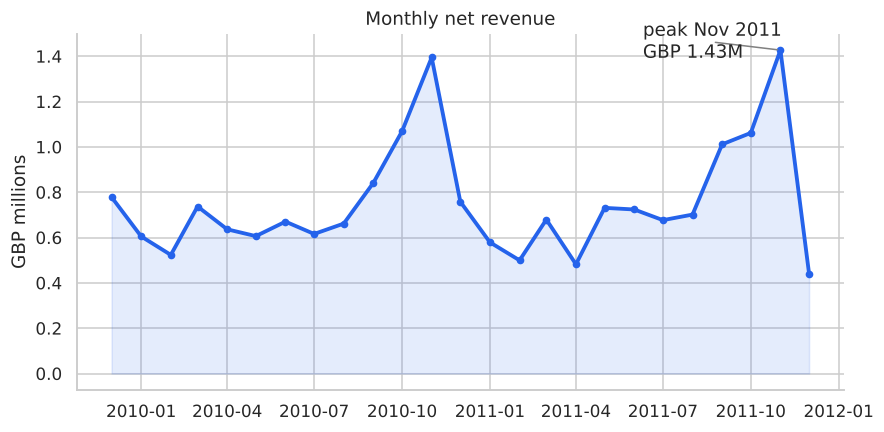

,month,net_revenue,orders,share_of_year
23,2011-11-01,"1,427,124.54",2751,0.08
11,2010-11-01,"1,394,601.80",2719,0.07
10,2010-10-01,"1,068,984.91",2244,0.06
22,2011-10-01,"1,061,701.22",2005,0.06
21,2011-09-01,"1,011,339.74",1818,0.05


In [3]:
m = eda.monthly_revenue(clean)
fig, ax = plt.subplots()
ax.plot(m["month"], m["net_revenue"] / 1e6, color="#2563eb", lw=2.5, marker="o", ms=4)
ax.fill_between(m["month"], m["net_revenue"] / 1e6, alpha=.12, color="#2563eb")
peak = m.loc[m["net_revenue"].idxmax()]
ax.annotate(f"peak {peak['month']:%b %Y}\nGBP {peak['net_revenue']/1e6:.2f}M", (peak["month"], peak["net_revenue"] / 1e6), xytext=(-90, -5), textcoords="offset points", arrowprops=dict(arrowstyle="-", color="grey"))
ax.set(title="Monthly net revenue", ylabel="GBP millions"); plt.show()
m.assign(share_of_year=lambda d: d.net_revenue / d.net_revenue.sum()).sort_values("net_revenue", ascending=False).head(5)

**Business reading.** A gift retailer: revenue climbs from September, peaks in Q4 (Christmas) and falls back in January. The final point is low because **Dec 2011 is incomplete** (data ends 9 Dec) - a classic trap. Plan stock, staff and marketing backwards from the peak.

## 3. Where does the money come from? (country revenue)

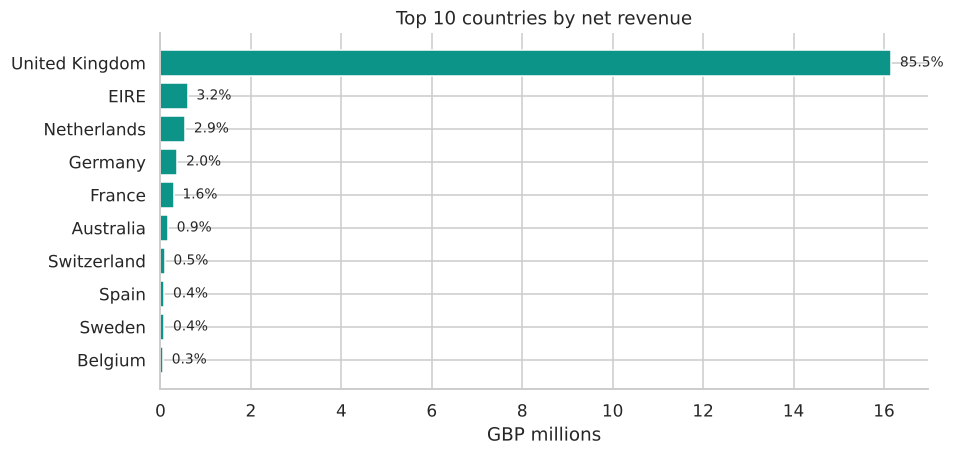

In [4]:
cr = eda.country_revenue(clean)
top = cr.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(top["Country"], top["net_revenue"] / 1e6, color="#0d9488")
for y, (v, s) in enumerate(zip(top["net_revenue"] / 1e6, top["share"])): ax.text(v, y, f"  {s:.1%}", va="center", fontsize=9)
ax.set(title="Top 10 countries by net revenue", xlabel="GBP millions"); plt.show()

**Reading.** One market dominates. That is a risk (dependence) and an opportunity (export growth), and it means *Country* will carry little signal in a model - one reason we left it out of the segmentation features.

## 4. Best-selling products (top 10 bar chart)

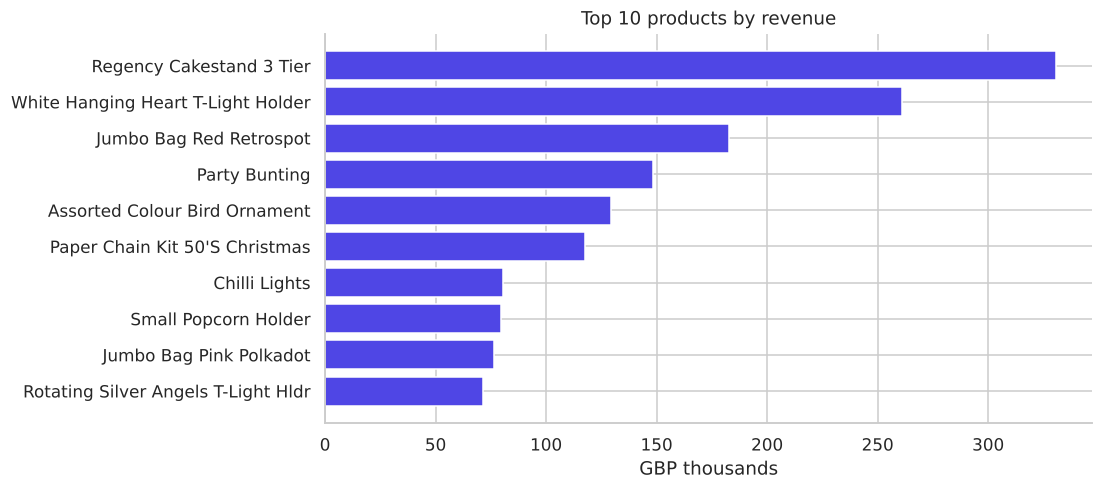

,Description,units,orders
3479,WORLD WAR 2 GLIDERS ASSTD DESIGNS,"106,139.00",1019
4129,JUMBO BAG RED RETROSPOT,"97,176.00",4013
609,PACK OF 72 RETROSPOT CAKE CASES,"94,884.00",3118
4151,WHITE HANGING HEART T-LIGHT HOLDER,"94,719.00",5464
1427,SMALL POPCORN HOLDER,"88,499.00",2322


In [5]:
tp = eda.top_products(clean, 10, by="revenue").iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(tp["Description"].str.title().str.slice(0, 38), tp["revenue"] / 1e3, color="#4f46e5")
ax.set(title="Top 10 products by revenue", xlabel="GBP thousands"); plt.show()
eda.top_products(clean, 5, by="units")[["Description", "units", "orders"]]

Top by **revenue** and top by **units** differ: cheap items sell in bulk, expensive items earn more per unit. Always say which one you mean.

## 5. Customers: purchasing frequency and spend (histograms)

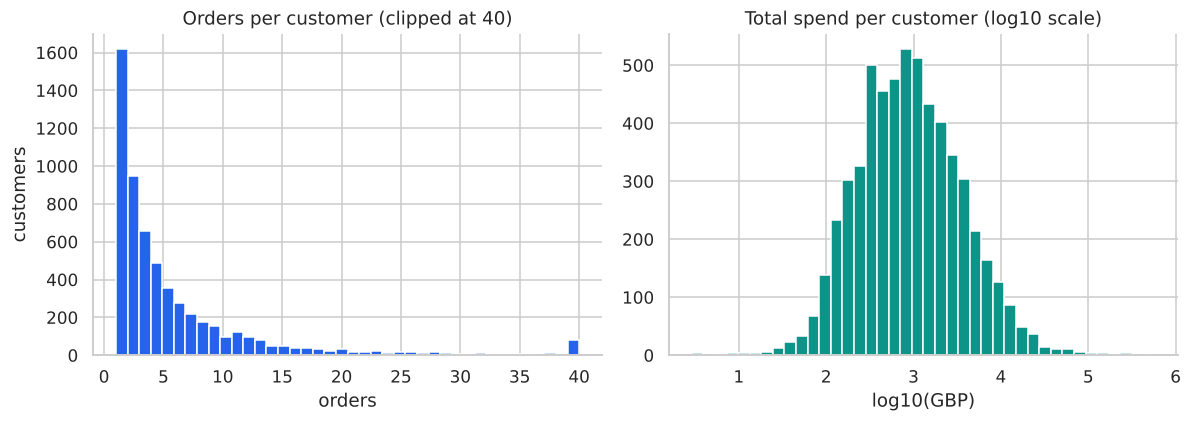

,orders per customer,spend per customer (GBP)
mean,6.25,"2,871.82"
median,3.00,855.58
std,12.75,"14,103.88"
skew,12.04,26.15
min,1.00,2.90
p95,20.00,"9,226.96"
max,373.00,"580,987.04"


In [6]:
orders = eda.customer_order_counts(clean)
spend = sales[sales.HasCustomer].groupby("CustomerID")["Revenue"].sum()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(orders.clip(upper=40), bins=40, color="#2563eb"); ax[0].set(title="Orders per customer (clipped at 40)", xlabel="orders", ylabel="customers")
ax[1].hist(np.log10(spend.clip(lower=1)), bins=40, color="#0d9488"); ax[1].set(title="Total spend per customer (log10 scale)", xlabel="log10(GBP)")
plt.tight_layout(); plt.show()
pd.DataFrame({"orders per customer": eda.distribution_stats(orders), "spend per customer (GBP)": eda.distribution_stats(spend)})

**Reading the table.** For both variables the **mean is far above the median** and **skew is well above 1**: a long right tail of very loyal, very valuable customers. Consequences we will act on:
* use the **median** (not the mean) to describe a "typical" customer;
* apply a **log transform** before K-Means, otherwise the biggest spenders dominate the distance calculation;
* expect revenue to be **concentrated** in a minority of customers: the next cell shows that the top 20% of customers produce roughly three-quarters of customer revenue.

In [7]:
s = spend.sort_values(ascending=False)
cum = s.cumsum() / s.sum()
for pct in (0.01, 0.05, 0.10, 0.20):
    print(f"top {pct:>4.0%} of customers produce {cum.iloc[int(len(s)*pct)-1]:.1%} of customer revenue")

top   1% of customers produce 31.2% of customer revenue
top   5% of customers produce 51.3% of customer revenue
top  10% of customers produce 63.4% of customer revenue
top  20% of customers produce 76.8% of customer revenue


## 6. Transaction quantity and box plots

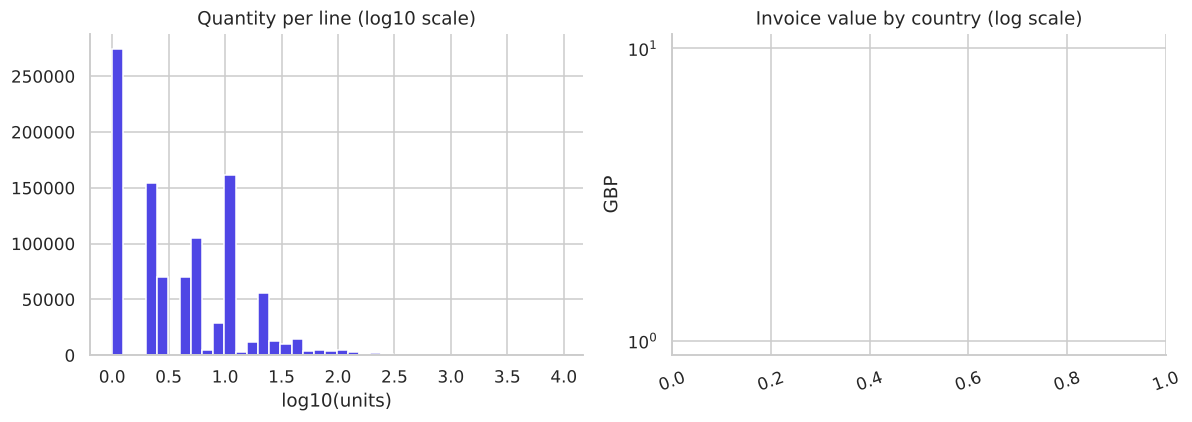

        Quantity per line
mean                10.89
median               4.00
std                 56.00
skew                63.48
min                  1.00
p95                 32.00
max              9,456.00


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(np.log10(sales["Quantity"]), bins=40, color="#4f46e5"); ax[0].set(title="Quantity per line (log10 scale)", xlabel="log10(units)")
inv = eda.weekday_hour_pattern(clean)
top5 = inv["revenue"].groupby(clean.drop_duplicates("InvoiceNo").set_index("InvoiceNo")["Country"]).sum().nlargest(5).index
box_df = inv.merge(clean.drop_duplicates("InvoiceNo")[["InvoiceNo", "Country"]], on="InvoiceNo")
box_df = box_df[box_df.Country.isin(top5) & (box_df.revenue > 0)]
sns.boxplot(data=box_df, x="Country", y="revenue", ax=ax[1], color="#93c5fd", fliersize=1.5); ax[1].set_yscale("log")
ax[1].set(title="Invoice value by country (log scale)", ylabel="GBP"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
print(pd.Series(eda.distribution_stats(sales["Quantity"])).round(2).to_frame("Quantity per line"))

**Box-plot reading.** The box (middle 50%) is small and sits low; the dots above it are the outliers - bulk wholesale orders. We **flag** very large lines (`IsOutlier`) rather than delete them: they are real customers, and the log transform plus robust models handle them.

## 7. Daily purchasing patterns

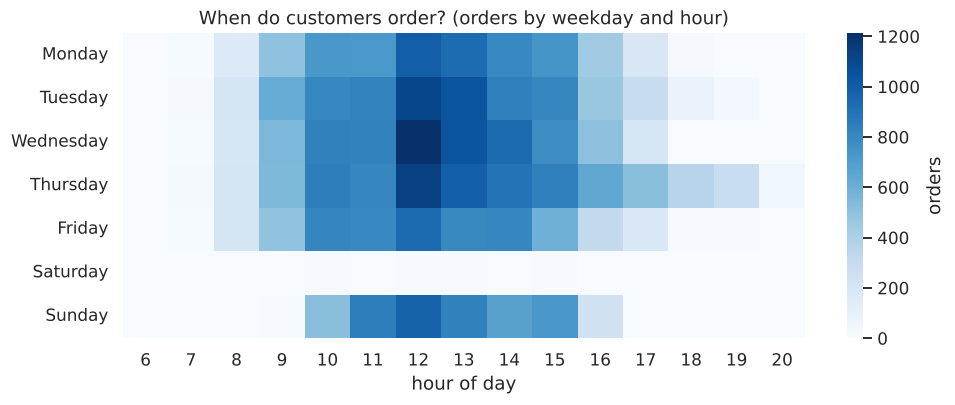

In [9]:
inv["weekday"] = pd.Categorical(inv["weekday"], ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"], ordered=True)
heat = inv.pivot_table(index="weekday", columns="hour", values="InvoiceNo" if "InvoiceNo" in inv else "revenue", aggfunc="count", observed=False)
fig, ax = plt.subplots(figsize=(10, 3.6))
sns.heatmap(heat, cmap="Blues", ax=ax, cbar_kws={"label": "orders"}); ax.set(title="When do customers order? (orders by weekday and hour)", xlabel="hour of day", ylabel="")
plt.show()

**Reading.** About two-thirds of orders are placed between 10:00 and 15:00, and **Saturday is almost empty** (only a few dozen invoices in two years) while Sunday is busy - the shop evidently does not process orders on Saturdays. Together with the huge baskets this suggests a substantial B2B (wholesale) customer base, not just consumers.

## 8. Correlation heatmap

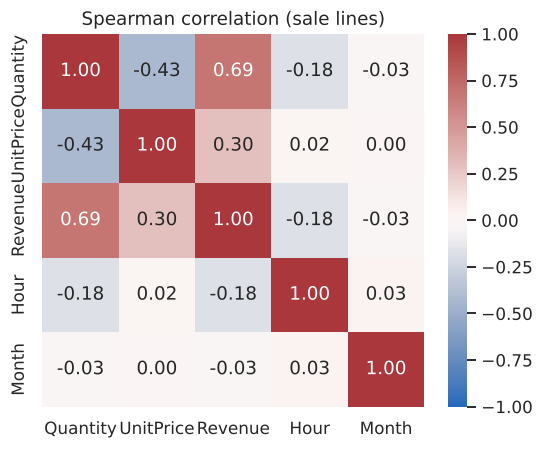

In [10]:
corr = eda.correlation_frame(clean)
fig, ax = plt.subplots(figsize=(5.6, 4.4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax); ax.set_title("Spearman correlation (sale lines)")
plt.show()

**Reading (values from this run).** `Revenue` is driven mainly by `Quantity` (about +0.69) and less by `UnitPrice` (about +0.30). `Quantity` and `UnitPrice` are **negatively** related (about -0.43): expensive items are bought in smaller numbers, cheap ones in bulk. `Hour` has a small negative link with quantity (about -0.18): later-in-the-day orders are slightly smaller. `Month` is near zero - which does **not** mean "no seasonality": correlation only measures *monotonic* relationships, and a Q4 peak is not monotonic in the month number.

## Check yourself
1. Why can the *median* order value be much lower than the *average* order value?
2. A colleague says "revenue crashed in December 2011". What is your reply?
3. Which transformation would you apply to `spend` before clustering, and why?